# 09 · Comparación BoW vs. Word2Vec vs. BETO

**Sección 5.3 del enunciado:** comparación de las tres representaciones de las reseñas.

| Representación | Tipo | Archivo |
|---|---|---|
| BoW (TF-IDF) | Dispersa | `tfidf.npz` (notebook 07) |
| Word2Vec | Densa estática (promedio de la reseña) | `embeddings_word2vec.npz` (notebook 07) |
| BETO [CLS] | Densa contextual | `embeddings_beto.npz` (notebook 08) |

Las tres se evalúan sobre **las mismas reseñas** y con **la misma partición de entrenamiento y prueba** (`random_state` = número de equipo).

Código: `src/comparacion.py`. Los resultados se ven también en el dashboard (`dashboard_app.py`, pestaña *Comparación de representaciones*).

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

# Raíz del proyecto: el notebook se ejecuta desde la carpeta notebooks/
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import comparacion as cp
import embeddings_w2v as ew

NUMERO_EQUIPO = 1          # <- cambiar por el número de equipo (igual que en los notebooks 07 y 08)
SEMILLA = NUMERO_EQUIPO

df = ew.cargar_corpus()
representaciones = cp.cargar_representaciones(df["id"])
for nombre, X in representaciones.items():
    print(f"{nombre}: {X.shape[0]} reseñas x {X.shape[1]} dimensiones")

BoW (TF-IDF): 16991 reseñas x 19777 dimensiones
Word2Vec: 16991 reseñas x 150 dimensiones
BETO [CLS]: 16991 reseñas x 768 dimensiones


---
## 1. Tarea de clasificación

Una **Logistic Regression** con cada representación, para clasificar:
- **polaridad** (positiva / negativa),
- **género principal** (5 géneros),
- **origen** del texto (traducido / nativo), la pregunta adicional del enunciado.

Se usa 80 % de las reseñas para entrenar y 20 % para medir la **accuracy**, con la misma partición para las tres representaciones.

In [3]:
clasificacion = cp.comparar_clasificacion(representaciones, df, semilla=SEMILLA)
clasificacion.pivot(index="representacion", columns="tarea", values="accuracy").round(3)

tarea,género,origen,polaridad
representacion,,,
BETO [CLS],0.625,0.987,0.882
BoW (TF-IDF),0.793,0.947,0.870
Word2Vec,0.708,0.967,0.882


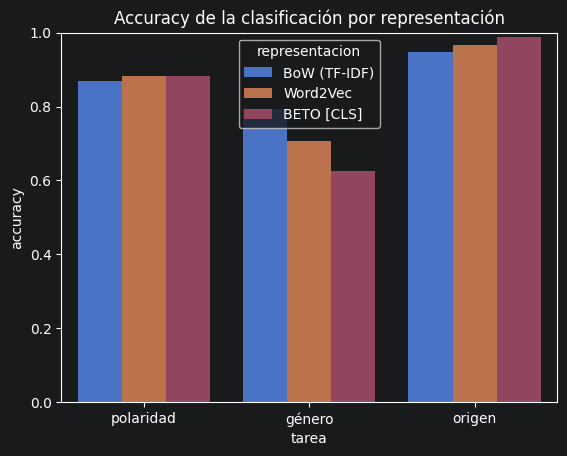

In [4]:
sns.barplot(clasificacion, x="tarea", y="accuracy", hue="representacion")
plt.ylim(0, 1)
plt.title("Accuracy de la clasificación por representación")
plt.show()

---
## 2. Clustering con K-Means

**K-Means** con cada representación, con tantos clusters como categorías reales (5 géneros, 2 polaridades, 2 orígenes), evaluado con el **Silhouette Score** (de −1 a 1; más alto = clusters más compactos y separados).

In [5]:
clustering = cp.comparar_clustering(representaciones, df, semilla=SEMILLA)
clustering.pivot(index="representacion", columns="categoria", values="silhouette").round(3)

categoria,género,origen,polaridad
representacion,,,
BETO [CLS],0.066,0.068,0.066
BoW (TF-IDF),0.061,0.107,0.109
Word2Vec,0.040,0.069,0.069


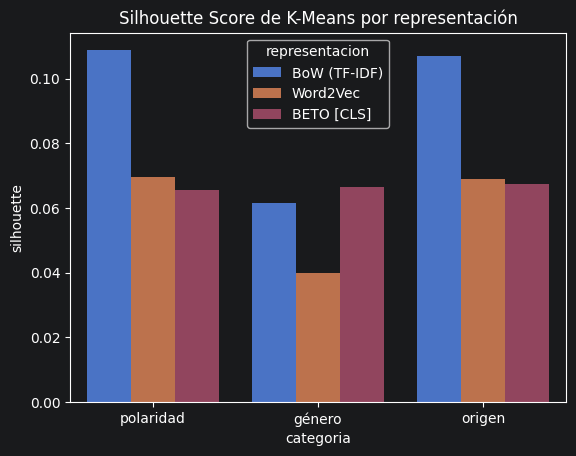

In [6]:
sns.barplot(clustering, x="categoria", y="silhouette", hue="representacion")
plt.title("Silhouette Score de K-Means por representación")
plt.show()

---
## 3. Visualización t-SNE

Proyección 2D de las reseñas con cada representación (tarda unos 3 minutos). Cada fila es una representación y cada columna colorea por una categoría.

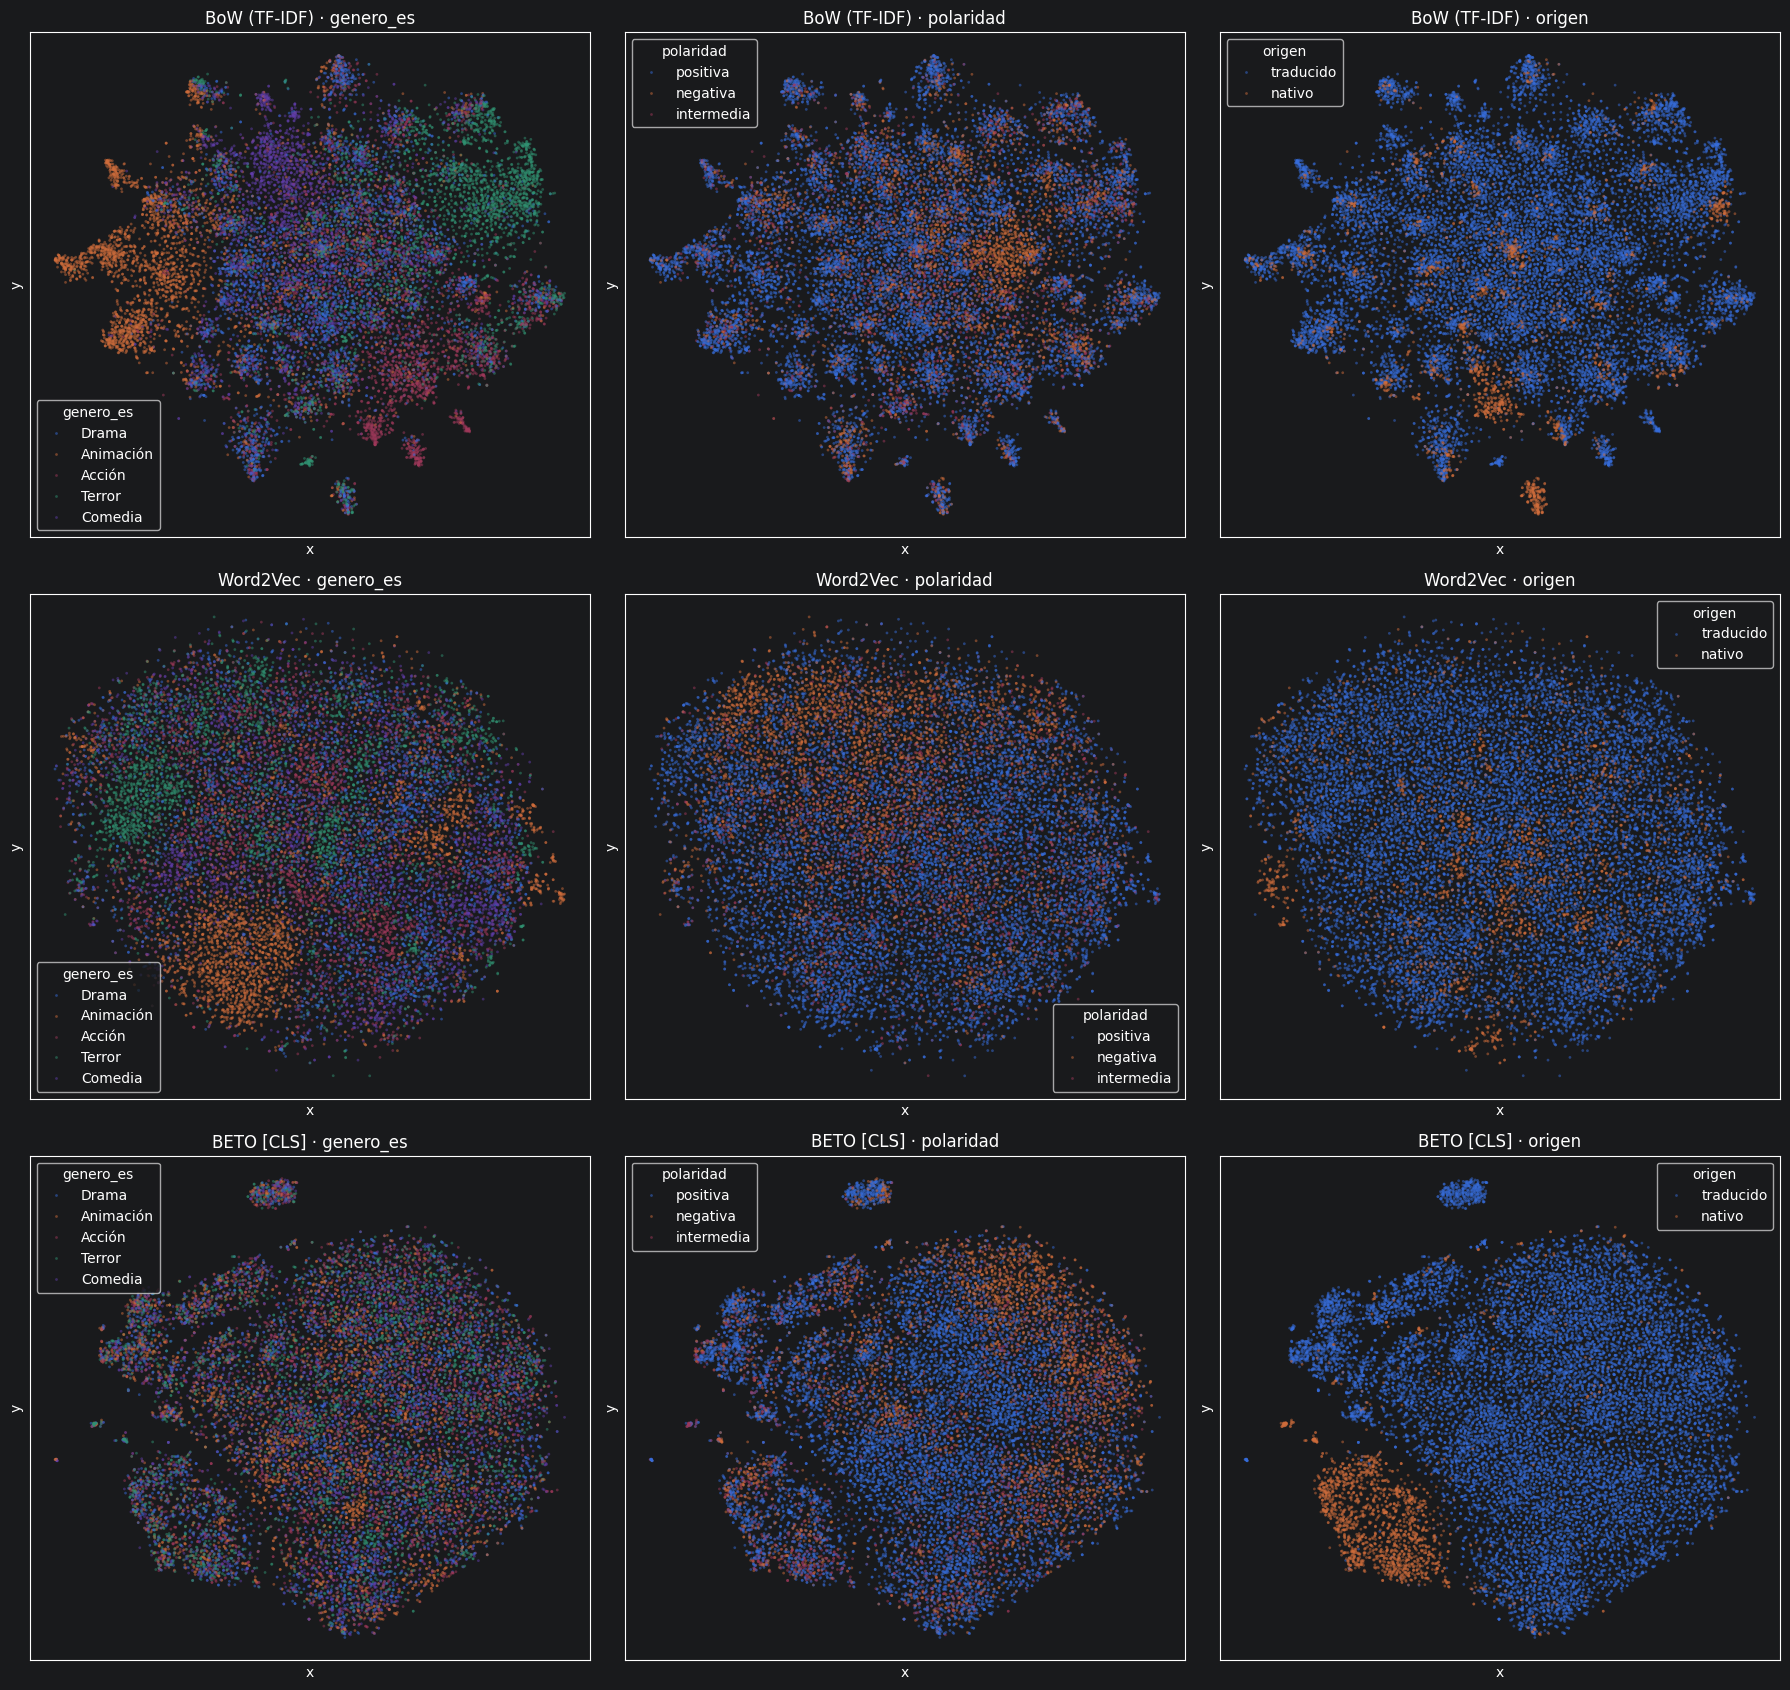

In [7]:
tsne = cp.proyectar_tsne(representaciones, df, semilla=SEMILLA)

categorias = ["genero_es", "polaridad", "origen"]
fig, axes = plt.subplots(3, 3, figsize=(18, 17))
for fila, nombre in enumerate(cp.REPRESENTACIONES):
    datos = tsne[tsne["representacion"] == nombre]
    for col, categoria in enumerate(categorias):
        ax = axes[fila, col]
        sns.scatterplot(datos, x="x", y="y", hue=categoria, s=4, alpha=0.5, linewidth=0, ax=ax)
        ax.set_title(f"{nombre} · {categoria}")
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

---
## 4. Guardado

Resultados para el dashboard: `comparacion_clasificacion.csv`, `comparacion_clustering.csv` y `comparacion_tsne.csv` en `data/results/`.

In [8]:
cp.guardar_resultados(clasificacion, clustering, tsne)
print("Resultados guardados en", cp.DIR_RESULTADOS.relative_to(RAIZ))

Resultados guardados en data\results
